# Retos del workshop RAG · notebook de arranque

Este notebook trae el punto de partida de algunos retos. Los bloques marcados con `TODO` son tuyos. Copia este archivo a `notebooks/04_challenges.ipynb` en tu repo.

## C1 · HNSW contra fuerza bruta con FAISS

Instala FAISS y ejecuta la línea base. Después completa los TODO.

In [1]:
%pip install -q faiss-cpu matplotlib

In [2]:
import time
import faiss
import numpy as np

d, n, nq, k = 64, 20_000, 200, 10
rng = np.random.default_rng(42)
xb = rng.random((n, d), dtype="float32")
xq = rng.random((nq, d), dtype="float32")

flat = faiss.IndexFlatL2(d)
flat.add(xb)
t0 = time.time(); _, I_true = flat.search(xq, k); t_flat = (time.time() - t0) / nq * 1000

def recall_at_k(I, I_true):
    return float(np.mean([len(set(a) & set(b)) / len(b) for a, b in zip(I, I_true)]))

rows = []
for M in (8, 16, 32):
    index = faiss.IndexHNSWFlat(d, M)
    index.hnsw.efConstruction = 100
    t0 = time.time(); index.add(xb); build_s = time.time() - t0
    for ef in (10, 16, 32, 64, 128, 256):
        index.hnsw.efSearch = ef
        t0 = time.time(); _, I = index.search(xq, k); ms = (time.time() - t0) / nq * 1000
        rows.append((M, ef, recall_at_k(I, I_true), ms, build_s))

print(f"exacto: {t_flat:.3f} ms/consulta")
for M, ef, rec, ms, b in rows:
    print(f"M={M:>2} ef={ef:>3} recall@{k}={rec:.3f}  {ms:.3f} ms/q  (build {b:.1f}s)")

exacto: 0.245 ms/consulta
M= 8 ef= 10 recall@10=0.168  0.065 ms/q  (build 4.8s)
M= 8 ef= 16 recall@10=0.242  0.059 ms/q  (build 4.8s)
M= 8 ef= 32 recall@10=0.355  0.084 ms/q  (build 4.8s)
M= 8 ef= 64 recall@10=0.510  0.126 ms/q  (build 4.8s)
M= 8 ef=128 recall@10=0.683  0.388 ms/q  (build 4.8s)
M= 8 ef=256 recall@10=0.819  0.564 ms/q  (build 4.8s)
M=16 ef= 10 recall@10=0.329  0.060 ms/q  (build 8.9s)
M=16 ef= 16 recall@10=0.425  0.079 ms/q  (build 8.9s)
M=16 ef= 32 recall@10=0.599  0.130 ms/q  (build 8.9s)
M=16 ef= 64 recall@10=0.770  0.256 ms/q  (build 8.9s)
M=16 ef=128 recall@10=0.905  0.469 ms/q  (build 8.9s)
M=16 ef=256 recall@10=0.971  1.004 ms/q  (build 8.9s)
M=32 ef= 10 recall@10=0.468  0.080 ms/q  (build 7.3s)
M=32 ef= 16 recall@10=0.579  0.098 ms/q  (build 7.3s)
M=32 ef= 32 recall@10=0.761  0.159 ms/q  (build 7.3s)
M=32 ef= 64 recall@10=0.909  0.239 ms/q  (build 7.3s)
M=32 ef=128 recall@10=0.983  0.449 ms/q  (build 7.3s)
M=32 ef=256 recall@10=0.998  0.879 ms/q  (build 7.3s)


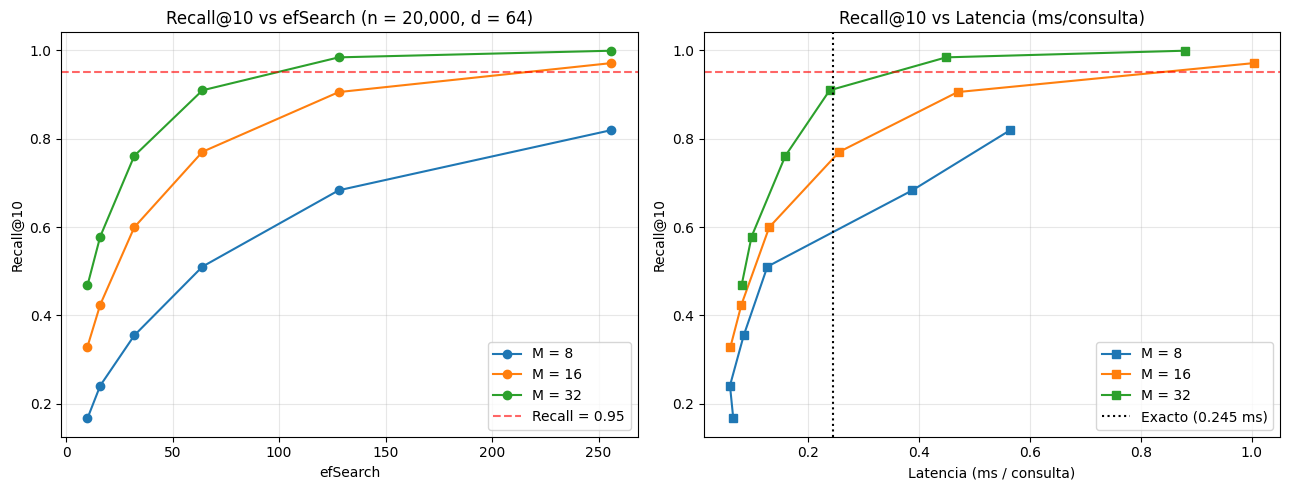

        n |   ef | Recall@10 | HNSW (ms) | Exacto (ms) |  Speedup | Build (s)
----------------------------------------------------------------------------
   20,000 |   32 |     0.600 |     0.100 |       0.486 |    4.88x |      7.7s
   20,000 |   64 |     0.780 |     0.358 |       0.486 |    1.36x |      7.7s
   20,000 |  128 |     0.922 |     0.534 |       0.486 |    0.91x |      7.7s
  100,000 |   32 |     0.378 |     0.200 |       3.854 |   19.30x |     31.9s
  100,000 |   64 |     0.531 |     0.171 |       3.854 |   22.57x |     31.9s
  100,000 |  128 |     0.703 |     0.281 |       3.854 |   13.73x |     31.9s
  500,000 |   32 |     0.213 |     0.109 |      11.465 |  105.15x |    185.3s
  500,000 |   64 |     0.328 |     0.198 |      11.465 |   57.79x |    185.3s
  500,000 |  128 |     0.469 |     0.343 |      11.465 |   33.45x |    185.3s


In [3]:
import matplotlib.pyplot as plt
import pandas as pd

# --- TODO 1: Graficar recall vs efSearch y recall vs latencia (para n = 20,000) ---
df_20k = pd.DataFrame(rows, columns=["M", "efSearch", "recall", "ms_query", "build_s"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

for M_val, group in df_20k.groupby("M"):
    ax1.plot(group["efSearch"], group["recall"], marker="o", label=f"M = {M_val}")
    ax2.plot(group["ms_query"], group["recall"], marker="s", label=f"M = {M_val}")

ax1.axhline(0.95, color="red", linestyle="--", alpha=0.6, label="Recall = 0.95")
ax1.set_title("Recall@10 vs efSearch (n = 20,000, d = 64)")
ax1.set_xlabel("efSearch")
ax1.set_ylabel("Recall@10")
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.axvline(t_flat, color="black", linestyle=":", label=f"Exacto ({t_flat:.3f} ms)")
ax2.axhline(0.95, color="red", linestyle="--", alpha=0.6)
ax2.set_title("Recall@10 vs Latencia (ms/consulta)")
ax2.set_xlabel("Latencia (ms / consulta)")
ax2.set_ylabel("Recall@10")
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.savefig("C1_hnsw_vs_flat.png", dpi=150)
plt.show()

# --- TODO 2: Repetir experimento con n = 20_000, 100_000 y 500_000 ---
# Comparamos IndexFlatL2 vs HNSW (M=16, efSearch=64 y 128) para ver desde qué n HNSW supera al exacto
resultados_n = []
for n_test in (20_000, 100_000, 500_000):
    xb_t = rng.random((n_test, d), dtype="float32")
    xq_t = rng.random((nq, d), dtype="float32")

    # Índice Exacto
    flat_t = faiss.IndexFlatL2(d)
    flat_t.add(xb_t)
    t0 = time.time()
    _, I_true_t = flat_t.search(xq_t, k)
    ms_flat = (time.time() - t0) / nq * 1000

    # Índice HNSW (M=16)
    hnsw_t = faiss.IndexHNSWFlat(d, 16)
    hnsw_t.hnsw.efConstruction = 100
    t0 = time.time()
    hnsw_t.add(xb_t)
    build_t = time.time() - t0

    for ef_test in (32, 64, 128):
        hnsw_t.hnsw.efSearch = ef_test
        t0 = time.time()
        _, I_hnsw = hnsw_t.search(xq_t, k)
        ms_hnsw = (time.time() - t0) / nq * 1000
        rec_t = recall_at_k(I_hnsw, I_true_t)
        resultados_n.append((n_test, ef_test, rec_t, ms_hnsw, ms_flat, ms_flat / ms_hnsw, build_t))

print(f"{'n':>9} | {'ef':>4} | {'Recall@10':>9} | {'HNSW (ms)':>9} | {'Exacto (ms)':>11} | {'Speedup':>8} | {'Build (s)':>9}")
print("-" * 76)
for r in resultados_n:
    print(f"{r[0]:>9,} | {r[1]:>4} | {r[2]:>9.3f} | {r[3]:>9.3f} | {r[4]:>11.3f} | {r[5]:>7.2f}x | {r[6]:>8.1f}s")

## C4 · Evaluación automática de la recuperación

Necesitas las variables del notebook 03 (`retriever`, `all_docs`, …) o reconstruirlas aquí.

Instalar los paquetes que faltan

In [4]:
# 1. Instalar las librerías del Notebook 03 que faltan en este entorno de Colab
%pip install -q langchain langchain-community langchain-text-splitters langchain-qdrant langchain-nvidia-ai-endpoints qdrant-client pypdf

import csv

def cargar_preguntas(ruta="eval/preguntas.csv"):
    with open(ruta, encoding="utf-8") as f:
        return list(csv.DictReader(f))

def hit_at_k(retriever, filas):
    hits = 0
    for r in filas:
        docs = retriever.invoke(r["pregunta"])
        ok = any(
            r["palabra_clave"].lower() in d.page_content.lower()
            and d.metadata["source"] == r["fuente_esperada"]
            for d in docs
        )
        hits += ok
    return hits / len(filas)

# Las 2 filas originales del profesor + 8 nuevas con las 5 columnas exactas:
filas_completas = [
    {
        "id": "1",
        "pregunta": "How many attention heads does the base Transformer use?",
        "fuente_esperada": "attention_paper.pdf",
        "palabra_clave": "8",
        "respuesta_esperada": "h = 8 heads con dk = dv = 64",
    },
    {
        "id": "2",
        "pregunta": "What are the two RAG model variants?",
        "fuente_esperada": "rag_paper.pdf",
        "palabra_clave": "RAG-Token",
        "respuesta_esperada": "RAG-Sequence y RAG-Token",
    },
    {
        "id": "3",
        "pregunta": "What is the dimension of keys and values dk in the base Transformer?",
        "fuente_esperada": "attention_paper.pdf",
        "palabra_clave": "64",
        "respuesta_esperada": "dk = dv = dmodel / h = 64",
    },
    {
        "id": "4",
        "pregunta": "What optimizer is used to train the Transformer model?",
        "fuente_esperada": "attention_paper.pdf",
        "palabra_clave": "Adam",
        "respuesta_esperada": "Adam optimizer con beta1=0.9, beta2=0.98",
    },
    {
        "id": "5",
        "pregunta": "What BLEU score did the big Transformer achieve on WMT 2014 English-to-German?",
        "fuente_esperada": "attention_paper.pdf",
        "palabra_clave": "28.4",
        "respuesta_esperada": "28.4 BLEU en WMT 2014 EN-DE",
    },
    {
        "id": "6",
        "pregunta": "What regularization technique is applied to the output of each sub-layer in the Transformer?",
        "fuente_esperada": "attention_paper.pdf",
        "palabra_clave": "dropout",
        "respuesta_esperada": "Residual dropout con P_drop = 0.1 y label smoothing",
    },
    {
        "id": "7",
        "pregunta": "What pre-trained seq2seq model is used as the parametric generator in RAG?",
        "fuente_esperada": "rag_paper.pdf",
        "palabra_clave": "BART",
        "respuesta_esperada": "BART-large (400M parámetros)",
    },
    {
        "id": "8",
        "pregunta": "What bi-encoder dense retriever does RAG use to retrieve documents?",
        "fuente_esperada": "rag_paper.pdf",
        "palabra_clave": "DPR",
        "respuesta_esperada": "Dense Passage Retriever (DPR) basado en BERT",
    },
    {
        "id": "9",
        "pregunta": "What library does RAG use for fast Maximum Inner Product Search (MIPS)?",
        "fuente_esperada": "rag_paper.pdf",
        "palabra_clave": "FAISS",
        "respuesta_esperada": "FAISS con índice HNSW",
    },
    {
        "id": "10",
        "pregunta": "Into how many word chunks was Wikipedia split for the non-parametric index in RAG?",
        "fuente_esperada": "rag_paper.pdf",
        "palabra_clave": "100",
        "respuesta_esperada": "Chunks disjuntos de 100 palabras (21M de documentos)",
    },
]

columnas = ["id", "pregunta", "fuente_esperada", "palabra_clave", "respuesta_esperada"]
with open("eval/preguntas.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=columnas)
    writer.writeheader()
    writer.writerows(filas_completas)

filas = cargar_preguntas("eval/preguntas.csv")
print(f"✅ Total de filas guardadas en eval/preguntas.csv: {len(filas)}")
for r in filas:
    print(f"  [{r['id']:>2}] ({r['fuente_esperada']}) {r['pregunta']} -> '{r['palabra_clave']}'")

✅ Total de filas guardadas en eval/preguntas.csv: 10
  [ 1] (attention_paper.pdf) How many attention heads does the base Transformer use? -> '8'
  [ 2] (rag_paper.pdf) What are the two RAG model variants? -> 'RAG-Token'
  [ 3] (attention_paper.pdf) What is the dimension of keys and values dk in the base Transformer? -> '64'
  [ 4] (attention_paper.pdf) What optimizer is used to train the Transformer model? -> 'Adam'
  [ 5] (attention_paper.pdf) What BLEU score did the big Transformer achieve on WMT 2014 English-to-German? -> '28.4'
  [ 6] (attention_paper.pdf) What regularization technique is applied to the output of each sub-layer in the Transformer? -> 'dropout'
  [ 7] (rag_paper.pdf) What pre-trained seq2seq model is used as the parametric generator in RAG? -> 'BART'
  [ 8] (rag_paper.pdf) What bi-encoder dense retriever does RAG use to retrieve documents? -> 'DPR'
  [ 9] (rag_paper.pdf) What library does RAG use for fast Maximum Inner Product Search (MIPS)? -> 'FAISS'
  [10] (rag_p

In [5]:
from langchain_nvidia_ai_endpoints import NVIDIAEmbeddings

# Esto imprime una lista con los objetos de los modelos de embeddings disponibles actualmente
print(NVIDIAEmbeddings.get_available_models())

[Model(id='snowflake/arctic-embed-l', model_type='embedding', client='NVIDIAEmbeddings', endpoint=None, aliases=['ai-arctic-embed-l'], supports_tools=False, supports_structured_output=False, supports_thinking=False, thinking_prefix=None, no_thinking_prefix=None, thinking_param_enable=None, thinking_param_disable=None, base_model=None, deprecated=True), Model(id='nvidia/nv-embedqa-e5-v5', model_type='embedding', client='NVIDIAEmbeddings', endpoint=None, aliases=None, supports_tools=False, supports_structured_output=False, supports_thinking=False, thinking_prefix=None, no_thinking_prefix=None, thinking_param_enable=None, thinking_param_disable=None, base_model=None, deprecated=False), Model(id='NV-Embed-QA', model_type='embedding', client='NVIDIAEmbeddings', endpoint='https://ai.api.nvidia.com/v1/retrieval/nvidia/embeddings', aliases=['ai-embed-qa-4'], supports_tools=False, supports_structured_output=False, supports_thinking=False, thinking_prefix=None, no_thinking_prefix=None, thinking_

/usr/local/lib/python3.13/dist-packages/langchain_nvidia_ai_endpoints/_common.py:231: UserWarning: An API key is required for the hosted NIM. This will become an error in the future.
  warnings.warn(


In [6]:
import os
import urllib.request
from google.colab import userdata
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_nvidia_ai_endpoints import NVIDIAEmbeddings
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_qdrant import QdrantVectorStore

# 1. Configurar API Key y modelo de embeddings de NVIDIA
os.environ["NVIDIA_API_KEY"] = userdata.get("NVIDIA_API_KEY")
embeddings = HuggingFaceEmbeddings(model_name="all-MiniLM-L6-v2")


# 2. Descargar y cargar los PDFs con los nombres exactos del CSV
PAPERS = {
    "attention_paper.pdf": "https://arxiv.org/pdf/1706.03762.pdf",
    "rag_paper.pdf": "https://arxiv.org/pdf/2005.11401.pdf",
}

os.makedirs("papers", exist_ok=True)
all_docs = []
for filename, url in PAPERS.items():
    filepath = os.path.join("papers", filename)
    if not os.path.exists(filepath):
        urllib.request.urlretrieve(url, filepath)
    loader = PyPDFLoader(filepath)
    docs_paper = loader.load()
    for d in docs_paper:
        d.metadata["source"] = filename
    all_docs.extend(docs_paper)

print(f"Páginas cargadas: {len(all_docs)}")

# 3. Evaluar hit@3 y hit@5 con chunk_size = 400, 900 y 1500
tabla_c4 = []
chunks = None  # Guardamos los de 900 para usarlos en el reto C6

for cs in (400, 900, 1500):
    overlap = int(cs * 0.13)
    splitter = RecursiveCharacterTextSplitter(chunk_size=cs, chunk_overlap=overlap)
    chunks_eval = splitter.split_documents(all_docs)
    if cs == 900:
        chunks = chunks_eval

    vs_eval = QdrantVectorStore.from_documents(
        documents=chunks_eval,
        embedding=embeddings,
        location=":memory:",
        collection_name=f"eval_c4_{cs}",
    )

    ret_3 = vs_eval.as_retriever(search_kwargs={"k": 3})
    ret_5 = vs_eval.as_retriever(search_kwargs={"k": 5})

    h3 = hit_at_k(ret_3, filas)
    h5 = hit_at_k(ret_5, filas)
    tabla_c4.append((cs, overlap, len(chunks_eval), h3, h5))

print("\n| chunk_size | overlap | chunks | hit@3 | hit@5 |")
print("|---|---|---|---|---|")
for cs, ov, n_ch, h3, h5 in tabla_c4:
    print(f"| {cs} | {ov} | {n_ch} | {h3:.2f} ({h3*100:.0f}%) | {h5:.2f} ({h5*100:.0f}%) |")

/tmp/ipykernel_27934/2384853902.py:4: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Páginas cargadas: 34

| chunk_size | overlap | chunks | hit@3 | hit@5 |
|---|---|---|---|---|
| 400 | 52 | 319 | 0.70 (70%) | 0.80 (80%) |
| 900 | 117 | 153 | 0.70 (70%) | 0.80 (80%) |
| 1500 | 195 | 96 | 0.60 (60%) | 0.80 (80%) |


## C6 · Persistencia del índice en disco

Punto de partida: cambia el cliente en memoria por uno con ruta.

In [7]:
import time
from qdrant_client import QdrantClient
from langchain_qdrant import QdrantVectorStore

COLLECTION_NAME = "academic_papers_nvidia"
DB_PATH = "./qdrant_data"

# 1. Comprobar si existe la colección abriendo y cerrando de inmediato el cliente local
client_check = QdrantClient(path=DB_PATH)
existe = client_check.collection_exists(COLLECTION_NAME)
client_check.close() # ¡Crucial para liberar el archivo en disco!
print("¿Ya existe la colección?", existe)

# 2. Indexar o reutilizar según corresponda
if not existe:
    print("Indexando documentos por primera vez en disco...")
    t_start = time.time()

    # QdrantVectorStore se encarga de crear el cliente y escribir en la ruta
    vectorstore_disk = QdrantVectorStore.from_documents(
        documents=chunks,
        embedding=embeddings,
        path=DB_PATH,
        collection_name=COLLECTION_NAME,
    )
    t_index = time.time() - t_start
    print(f"⏱️ Tiempo de indexación y guardado: {t_index:.2f} segundos")
else:
    print("⚡ Reutilizando colección existente desde disco...")
    t_start = time.time()

    # Si ya existe, abrimos un nuevo cliente limpio para leer la colección existente
    client_read = QdrantClient(path=DB_PATH)
    vectorstore_disk = QdrantVectorStore(
        client=client_read,
        collection_name=COLLECTION_NAME,
        embedding=embeddings,
    )
    t_open = time.time() - t_start
    print(f"⚡ Tiempo de reapertura sin reindexar: {t_open:.4f} segundos")

# 3. Comprobación de que responde correctamente
retriever_disk = vectorstore_disk.as_retriever(search_kwargs={"k": 2})
docs_prueba = retriever_disk.invoke("What is the Transformer architecture?")
print(f"✅ Búsqueda exitosa. Chunks recuperados: {len(docs_prueba)}")

¿Ya existe la colección? True
⚡ Reutilizando colección existente desde disco...
⚡ Tiempo de reapertura sin reindexar: 0.0477 segundos
✅ Búsqueda exitosa. Chunks recuperados: 2
